In [ ]:
#imports
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression , Lasso , LassoCV , ElasticNetCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import  make_pipeline
import matplotlib.pyplot as plt
import seaborn as sns



In [24]:
#reading file
base_path = Path.cwd().parent
df = pd.read_parquet(f"{base_path}/data/processed/clean_telemetry.parquet")

In [25]:
#segmenting track segments by most important curves on monza and aggregating data to these curves for ml model
track = {"Rettifilo" : (130,185), "Roggia":(325,385) , "Lesmo":(405,530) , "Ascari" : (650 , 740) , "Parabolica" : (860,970)}
track_parts = []
for curve , (start , end) in track.items():
    curves = df["track_segment"].between(start , end)
    section = df[curves]
    mlData = section.groupby(["session" , "completedLaps"]).agg(min_speed = ("speedKmh" , min) , exit_speed=("speedKmh" , "last"),mean_speed=("speedKmh" , "mean"),mean_gas=("gas" , "mean") , mean_brake=("brake" , "mean"))
    mlData = mlData.add_prefix(f"{curve}_")
    track_parts.append(mlData)

monza = pd.concat(track_parts , axis=1)
print(monza)

                       Rettifilo_min_speed  Rettifilo_exit_speed  \
session completedLaps                                              
1       5                        64.864954            120.148296   
        6                        63.819803            131.560845   
        9                        52.487254            131.181325   
        12                       46.796174            128.613419   
        14                       63.439513            130.738285   
2       1                        45.883944            127.045503   
        5                        49.772368            126.236040   
        7                        49.682015            129.766464   
        8                        55.403060            133.633434   
        9                        52.975267            132.030350   
3       1                        53.325133            129.754855   
        2                        57.370324            130.630146   
        3                        52.025585      

In [26]:
#getting set x as monza data and set u as laps and create set for training and testing
X = monza
y = df.groupby(["session" , "completedLaps"])["cleanLaps"].first().round(3)
X_train  , X_test , y_train , y_test = train_test_split(X ,y , test_size=0.2 , random_state=42)

In [27]:
#training Linear Regression model
model_lr = LinearRegression()
model_lr.fit(X_train , y_train)
y_pred_lr = model_lr.predict(X_test)
mae_lr = mean_absolute_error(y_test , y_pred_lr)
r2_lr = r2_score(y_test , y_pred_lr)
cv_mae_rl = -cross_val_score(model_lr , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
print(mae_lr , r2_lr , cv_mae_rl)

0.9959366357092299 0.734595734955745 3.9028616834702112


In [ ]:
#training Random Forest model
model_rf = RandomForestRegressor(random_state=42)
model_rf.fit(X_train , y_train)
y_pred_rf = model_rf.predict(X_test)
mae_rf = mean_absolute_error(y_test , y_pred_rf)
r2_rf = r2_score(y_test , y_pred_rf)
cv_mae_rf = -cross_val_score(model_rf , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
print(mae_rf , r2_rf , cv_mae_rf)


1.5692100000000002 0.4307233627209559 0.9070574285714276


In [29]:
#training Gradient Boost model
model_gb = GradientBoostingRegressor(random_state=42)
model_gb.fit(X_train , y_train)
y_pred_gb = model_gb.predict(X_test)
mae_gb = mean_absolute_error(y_test , y_pred_gb)
r2_gb = r2_score(y_test , y_pred_gb)
cv_mae_gb = -cross_val_score(model_gb , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
print(mae_gb , r2_gb , cv_mae_gb)


1.4287441252257946 0.5018702452198363 1.0202339708257209


In [30]:
#training Lasso model 
model_l = make_pipeline(StandardScaler() , Lasso(alpha = 0.023636363636363636))
model_l.fit(X_train , y_train)
y_pred_l = model_l.predict(X_test)
mae_l = mean_absolute_error(y_test , y_pred_l)
r2_l = r2_score(y_test , y_pred_l)
cv_mae_l = -cross_val_score(model_l , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
coef = model_l[-1].coef_
print(mae_l , r2_l , cv_mae_l)

1.0322187140886467 0.7601723246977282 0.6934391173496294


In [31]:
#training LassoCv model
model_l_cv = make_pipeline(StandardScaler() , LassoCV(alphas = np.linspace(0.01 , 0.1, 100) , cv=5 , random_state=42))
model_l_cv.fit(X_train , y_train)
y_pred_l_cv = model_l_cv.predict(X_test)
mae_l_cv = mean_absolute_error(y_test , y_pred_l_cv)
r2_l_cv = r2_score(y_test , y_pred_l_cv)
cv_mea_cv = -cross_val_score(model_l_cv , X , y ,cv=5 , scoring="neg_mean_absolute_error").mean()
coef_cv = model_l_cv[-1].coef_
alpha_cv = model_l_cv[-1].alpha_

In [40]:
#training ElasticNet model
model_e=make_pipeline(StandardScaler() , ElasticNetCV(alphas = np.linspace(0.01 ,0.1, 10) , cv=5 , random_state=42 , l1_ratio=np.linspace(0.01 , 0.5 ,100) , max_iter=1000))
model_e.fit(X_train , y_train)
y_pred_e = model_e.predict(X_test)
mae_e = mean_absolute_error(y_test , y_pred_e)
r2_e = r2_score(y_test , y_pred_e)
cv_mea_e = -cross_val_score(model_e , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
coef_e = model_e[-1].coef_
best_alpha = model_e[-1].alpha_
best_l1 = model_e[-1].l1_ratio_

               Model       MAE        R2    CV_MAE
0  Linear Regression  0.995937  0.734596  3.902862
1      Random Forest  1.569210  0.430723  0.907057
2  Gradient Boosting  1.428744  0.501870  1.020234
3              Lasso  1.032219  0.760172  0.693439
4            LassoCv  1.032375  0.734380  0.721807
5         ElasticNet  0.961063  0.775923  0.665524
0.01 0.1 0.01


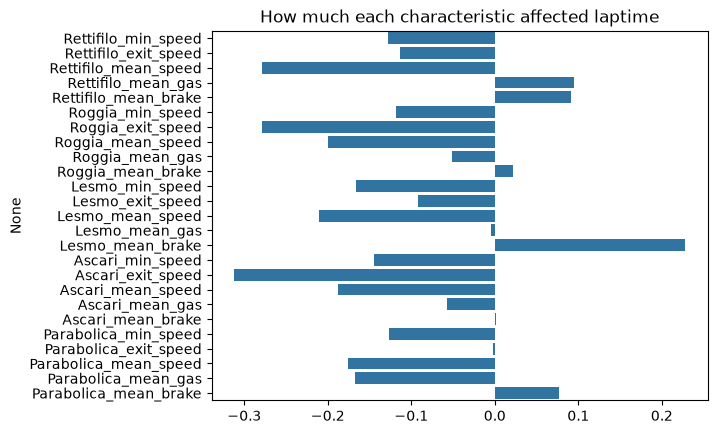

In [41]:
#printing result as well as plot of characteristics of best performing model
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "Gradient Boosting" , "Lasso" , "LassoCv" , "ElasticNet"],
    "MAE": [mae_lr, mae_rf, mae_gb , mae_l , mae_l_cv , mae_e],
    "R2": [r2_lr, r2_rf, r2_gb , r2_l , r2_l_cv , r2_e],
    "CV_MAE": [cv_mae_rl, cv_mae_rf, cv_mae_gb , cv_mae_l , cv_mea_cv , cv_mea_e],
})
sns.barplot(x=coef_e, y=X.columns )
print(results)
print(alpha_cv , best_alpha , best_l1)
plt.title("How much each characteristic affected laptime")
plt.show()


In [ ]:
#installing package automl for this notebook
%pip install mljar-supervised


  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached markupsafe-3.0.4-cp313-cp313-win_amd64.whl.metadata (2.8 kB)
   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ----- ---------------------------------- 12.6/100.2 MB 65.1 MB/s eta 0:00:02
   --------- ------------------------------ 24.1/100.2 MB 60.2 MB/s eta 0:00:02
   -------------- ------------------------- 35.9/100.2 MB 59.2 MB/s eta 0:00:02
   ------------------- -------------------- 49.0/100.2 MB 59.8 MB/s eta 0:00:01
   ----------------------- ---------------- 59.0/100.2 MB 57.0 MB/s eta 0:00:01
   ---------------------------- ----------- 71.0/100.2 MB 57.2


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
#running automl on mode compete with total time limit 3 minutes
from supervised.automl import AutoML

automl = AutoML(mode="Compete",total_time_limit=180, eval_metric="mae", random_state=42)
automl.fit(X_train, y_train)
y_pred_aml = automl.predict(X_test)
mae_aml = mean_absolute_error(y_test , y_pred_aml)
r2_aml = r2_score(y_test , y_pred_aml)
# cv_mea_aml = -cross_val_score(automl , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
print(mae_aml , r2_aml , cv_mea_aml)


AutoML directory: AutoML_8
The task is regression with evaluation metric mae
AutoML will use algorithms: ['Decision Tree', 'Linear', 'Random Forest', 'Extra Trees', 'LightGBM', 'Xgboost', 'CatBoost', 'Neural Network', 'Nearest Neighbors']
AutoML is generating and selecting models automatically. Review outputs before important use.
AutoML will stack models
AutoML will ensemble available models
AutoML steps: ['adjust_validation', 'simple_algorithms', 'default_algorithms', 'not_so_random', 'golden_features', 'kmeans_features', 'insert_random_feature', 'features_selection', 'hill_climbing_1', 'hill_climbing_2', 'boost_on_errors', 'ensemble', 'stack', 'ensemble_stacked']
* Step adjust_validation will try to check up to 1 model


c:\Users\kubad\Desktop\programowanie\programowanie\programowanie zaawnasowane\zaliczenie\env\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.


1_DecisionTree mae 0.505833 trained in 0.47 seconds
Adjust validation. Remove: 1_DecisionTree
*** Disable stacking for small dataset (nrows < 500)
Validation strategy: 5-fold CV Shuffle
* Step simple_algorithms will try to check up to 4 models


c:\Users\kubad\Desktop\programowanie\programowanie\programowanie zaawnasowane\zaliczenie\env\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
c:\Users\kubad\Desktop\programowanie\programowanie\programowanie zaawnasowane\zaliczenie\env\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
c:\Users\kubad\Desktop\programowanie\programowanie\programowanie zaawnasowane\zaliczenie\env\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always 

1_DecisionTree mae 1.031086 trained in 2.56 seconds


c:\Users\kubad\Desktop\programowanie\programowanie\programowanie zaawnasowane\zaliczenie\env\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
c:\Users\kubad\Desktop\programowanie\programowanie\programowanie zaawnasowane\zaliczenie\env\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
c:\Users\kubad\Desktop\programowanie\programowanie\programowanie zaawnasowane\zaliczenie\env\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always 

2_DecisionTree mae 0.963859 trained in 2.26 seconds
3_DecisionTree mae 0.844499 trained in 2.07 seconds
4_Linear mae 4.383164 trained in 2.57 seconds
* Step default_algorithms will try to check up to 7 models
5_Default_LightGBM mae 0.97003 trained in 2.29 seconds
6_Default_Xgboost mae 0.901664 trained in 2.62 seconds
7_Default_CatBoost mae 0.800349 trained in 4.64 seconds
8_Default_NeuralNetwork mae 0.604013 trained in 2.69 seconds
9_Default_RandomForest mae 0.92852 trained in 4.44 seconds
10_Default_ExtraTrees mae 0.97003 trained in 4.0 seconds
11_Default_NearestNeighbors mae 0.714 trained in 2.6 seconds
* Step not_so_random will try to check up to 61 models
21_LightGBM mae 0.97003 trained in 2.26 seconds
12_Xgboost mae 0.719614 trained in 3.13 seconds
30_CatBoost mae 0.819002 trained in 4.99 seconds
39_RandomForest mae 0.918161 trained in 4.33 seconds
48_ExtraTrees mae 0.97003 trained in 4.19 seconds
57_NeuralNetwork mae 0.931956 trained in 2.78 seconds
66_NearestNeighbors mae 0.7849